# 01 - Exploratory Data Analysis: GSE120584 (serum miRNA)

**Specific Aim 1.3.** Explore the training data before modeling.

- Data: GSE120584 serum miRNA (3D-Gene array, log2, normalized by submitters)
- **Training split only.** The 20% held-out test set is not loaded here (see `docs/analysis_plan.md`).

Sections:
1. Samples and clinical variables
2. Detection and sample quality
3. Feature filtering
4. PCA / t-SNE and outliers
5. AD vs NC: univariate differences, with and without age adjustment
6. Age-related miRNAs
7. Known AD ncRNAs
8. Summary and outputs

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

from utils import load_dataset, load_known_ncrnas, SEED, FIGURES, ROOT

FIG = FIGURES / "01_eda"
FIG.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "results" / "tables"
OUT.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
DX_ORDER = ["NC", "MCI", "AD", "DLB", "VaD"]
PALETTE = {"NC": "#4C72B0", "MCI": "#55A868", "AD": "#C44E52", "DLB": "#8172B2", "VaD": "#CCB974"}

def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Samples and clinical variables

In [2]:
X, clin = load_dataset("GSE120584_serum", split="train")
print(f"Training samples: {X.shape[0]}, miRNAs: {X.shape[1]}")
clin["diagnosis"].value_counts().reindex(DX_ORDER)

Training samples: 1280, miRNAs: 2562


diagnosis
NC     230
MCI     26
AD     816
DLB    135
VaD     73
Name: count, dtype: int64

In [3]:
summary = clin.groupby("diagnosis").agg(
    n=("age", "size"),
    age_mean=("age", "mean"),
    age_sd=("age", "std"),
    female_pct=("sex", lambda s: 100 * (s == "female").mean()),
    apoe4_carrier_pct=("apoe4", lambda s: 100 * (s > 0).mean()),
).reindex(DX_ORDER).round(1)
summary

,n,age_mean,age_sd,female_pct,apoe4_carrier_pct
diagnosis,,,,,
NC,230,71.9,6.3,47.4,18.7
MCI,26,76.5,5.3,76.9,38.5
AD,816,79.1,6.2,70.0,43.0
DLB,135,79.3,6.0,60.0,30.4
VaD,73,79.0,6.5,41.1,24.7


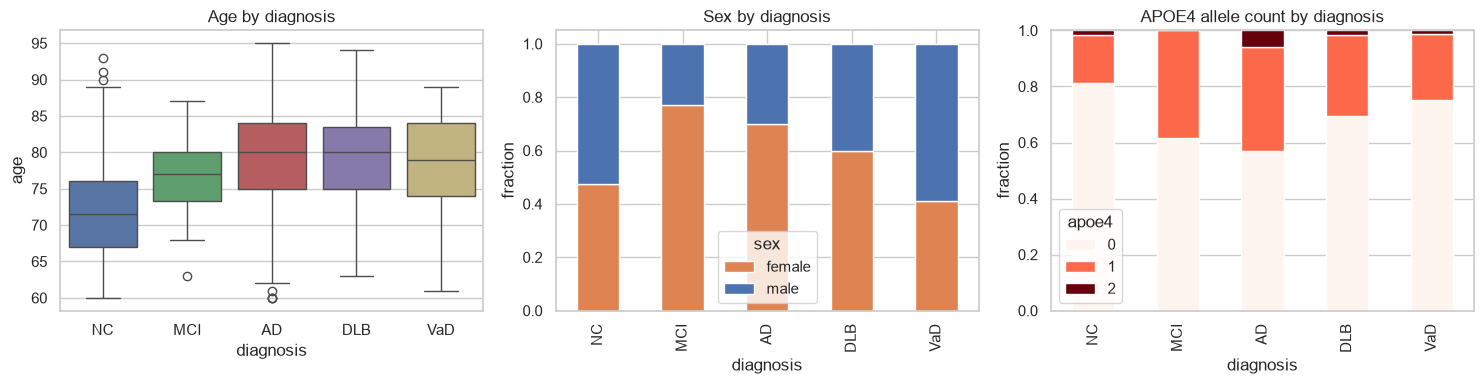

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=clin, x="diagnosis", y="age", order=DX_ORDER, hue="diagnosis", legend=False, palette=PALETTE, ax=axes[0])
axes[0].set_title("Age by diagnosis")
pd.crosstab(clin["diagnosis"], clin["sex"], normalize="index").reindex(DX_ORDER).plot(
    kind="bar", stacked=True, ax=axes[1], color=["#DD8452", "#4C72B0"])
axes[1].set_title("Sex by diagnosis"); axes[1].set_ylabel("fraction")
pd.crosstab(clin["diagnosis"], clin["apoe4"], normalize="index").reindex(DX_ORDER).plot(
    kind="bar", stacked=True, ax=axes[2], colormap="Reds")
axes[2].set_title("APOE4 allele count by diagnosis"); axes[2].set_ylabel("fraction")
plt.tight_layout(); savefig("clinical_overview"); plt.show()

In [5]:
# Confounder tests: AD vs NC
ad, nc = clin[clin.diagnosis == "AD"], clin[clin.diagnosis == "NC"]
t = stats.mannwhitneyu(ad.age, nc.age)
chi_sex = stats.chi2_contingency(pd.crosstab(clin.loc[clin.diagnosis.isin(["AD", "NC"]), "diagnosis"],
                                             clin.loc[clin.diagnosis.isin(["AD", "NC"]), "sex"]))
chi_apoe = stats.chi2_contingency(pd.crosstab(clin.loc[clin.diagnosis.isin(["AD", "NC"]), "diagnosis"],
                                              clin.loc[clin.diagnosis.isin(["AD", "NC"]), "apoe4"] > 0))
print(f"Age AD vs NC: {ad.age.mean():.1f} vs {nc.age.mean():.1f} y, Mann-Whitney p = {t.pvalue:.1e}")
print(f"Sex AD vs NC: chi2 p = {chi_sex.pvalue:.1e}")
print(f"APOE4 carrier AD vs NC: chi2 p = {chi_apoe.pvalue:.1e}")

Age AD vs NC: 79.1 vs 71.9 y, Mann-Whitney p = 1.2e-43
Sex AD vs NC: chi2 p = 3.7e-10
APOE4 carrier AD vs NC: chi2 p = 3.0e-11


**Interpretation.** Controls are much younger than AD patients, so age is a strong confounder. Any miRNA
that changes with age will look "AD-related". This is why sections 5-6 adjust for age, and why the
modeling notebook compares against an age + sex + APOE4 baseline.

## 2. Detection and sample quality

The submitters replaced signals that were not above background with a fixed low value
(the sample's minimum). So in each sample, values equal to the sample minimum mean **"not detected"**.

In [6]:
sample_min = X.min(axis=1)
detected = X.sub(sample_min, axis=0) > 1e-6          # True = detected above background
clin["detect_rate"] = detected.mean(axis=1)
mirna_detect = detected.mean(axis=0)

print(f"Overall fraction of detected values: {detected.values.mean():.2f}")
print(f"Per-sample detection rate: median {clin.detect_rate.median():.2f}, "
      f"range {clin.detect_rate.min():.2f}-{clin.detect_rate.max():.2f}")

Overall fraction of detected values: 0.49
Per-sample detection rate: median 0.49, range 0.15-0.81


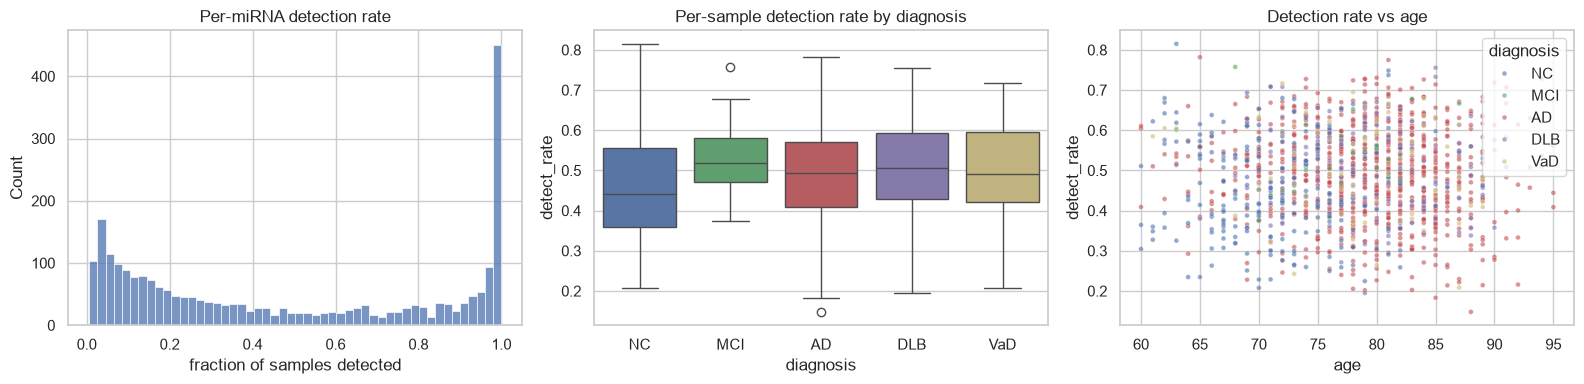

Detection rate AD vs NC: Mann-Whitney p = 1.6e-04
Spearman detection rate vs age: rho = -0.01


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(mirna_detect, bins=50, ax=axes[0])
axes[0].set_title("Per-miRNA detection rate"); axes[0].set_xlabel("fraction of samples detected")
sns.boxplot(data=clin, x="diagnosis", y="detect_rate", order=DX_ORDER, hue="diagnosis", legend=False, palette=PALETTE, ax=axes[1])
axes[1].set_title("Per-sample detection rate by diagnosis")
sns.scatterplot(data=clin, x="age", y="detect_rate", hue="diagnosis", palette=PALETTE,
                hue_order=DX_ORDER, s=12, alpha=.6, ax=axes[2])
axes[2].set_title("Detection rate vs age")
plt.tight_layout(); savefig("detection"); plt.show()

p = stats.mannwhitneyu(clin.loc[clin.diagnosis == "AD", "detect_rate"],
                       clin.loc[clin.diagnosis == "NC", "detect_rate"]).pvalue
print(f"Detection rate AD vs NC: Mann-Whitney p = {p:.1e}")
print(f"Spearman detection rate vs age: rho = {stats.spearmanr(clin.age, clin.detect_rate)[0]:.2f}")

**Why this matters.** If detection rate (a technical sample-quality measure) differs between AD and NC, a model
could learn sample quality instead of biology. If it does, consider adding `detect_rate` as a covariate,
or check that top miRNAs are not simply the ones that are "detected vs not detected" more often in one group.

## 3. Feature filtering

Keep miRNAs detected in at least **`MIN_DETECT`** of training samples. This filter is unsupervised
(doesn't use labels), so applying it on the whole training split does not leak label information.
**[DECIDE]** final threshold, see `docs/analysis_plan.md` section 3.

In [8]:
for thr in [0.5, 0.7, 0.8, 0.9, 1.0]:
    print(f"detected in >= {thr:.0%} of samples: {(mirna_detect >= thr).sum():5d} miRNAs")

MIN_DETECT = 0.8
keep = mirna_detect[mirna_detect >= MIN_DETECT].index
Xf = X[keep]
print(f"\nUsing MIN_DETECT = {MIN_DETECT}: {Xf.shape[1]} miRNAs kept")

detected in >= 50% of samples:  1152 miRNAs
detected in >= 70% of samples:   932 miRNAs
detected in >= 80% of samples:   817 miRNAs
detected in >= 90% of samples:   681 miRNAs
detected in >= 100% of samples:   241 miRNAs

Using MIN_DETECT = 0.8: 817 miRNAs kept


## 4. PCA, t-SNE and outliers

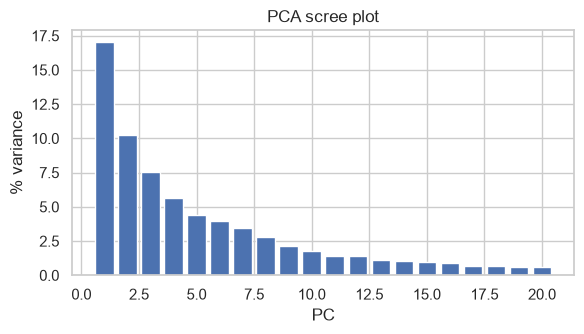

In [9]:
Z = StandardScaler().fit_transform(Xf)
pca = PCA(n_components=20, random_state=SEED).fit(Z)
pcs = pd.DataFrame(pca.transform(Z)[:, :10], index=Xf.index, columns=[f"PC{i+1}" for i in range(10)])
pcs = pcs.join(clin)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(range(1, 21), 100 * pca.explained_variance_ratio_)
ax.set_xlabel("PC"); ax.set_ylabel("% variance"); ax.set_title("PCA scree plot")
plt.tight_layout(); savefig("pca_scree"); plt.show()

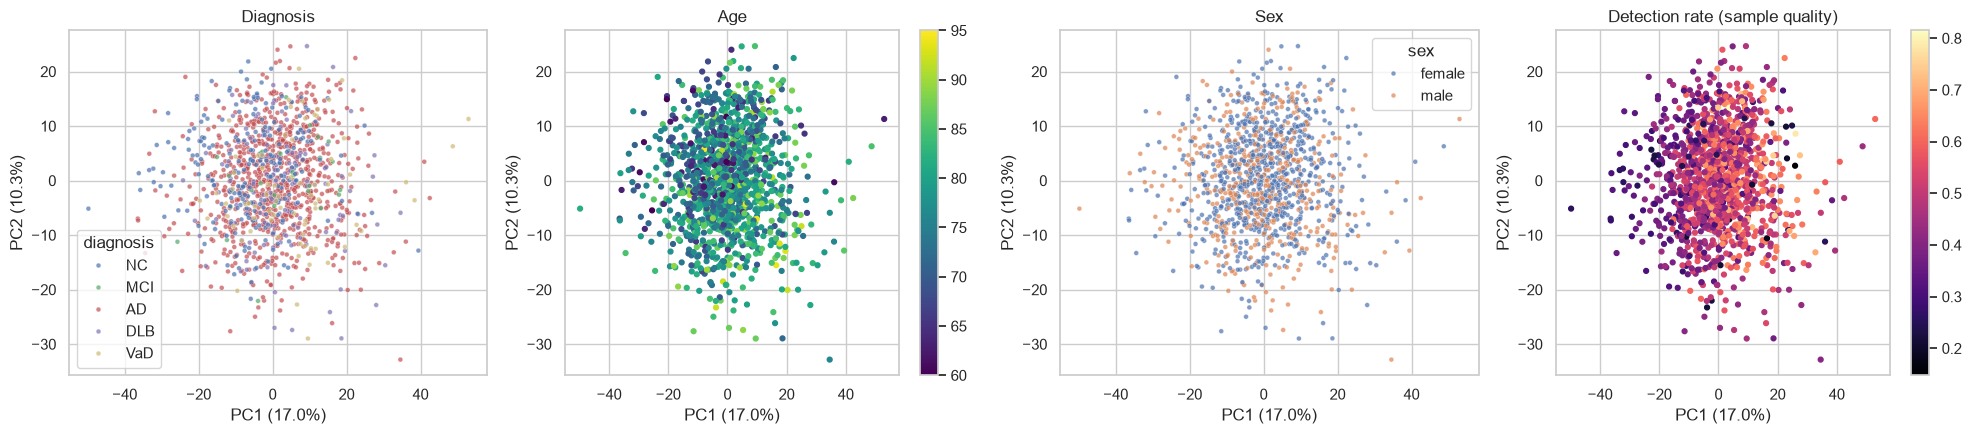

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="diagnosis", hue_order=DX_ORDER, palette=PALETTE,
                s=12, alpha=.7, ax=axes[0]); axes[0].set_title("Diagnosis")
sc = axes[1].scatter(pcs.PC1, pcs.PC2, c=pcs.age, cmap="viridis", s=12); plt.colorbar(sc, ax=axes[1])
axes[1].set_title("Age")
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="sex", s=12, alpha=.7, ax=axes[2]); axes[2].set_title("Sex")
sc = axes[3].scatter(pcs.PC1, pcs.PC2, c=pcs.detect_rate, cmap="magma", s=12); plt.colorbar(sc, ax=axes[3])
axes[3].set_title("Detection rate (sample quality)")
for a in axes:
    a.set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}%)")
    a.set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}%)")
plt.tight_layout(); savefig("pca_pc1_pc2"); plt.show()

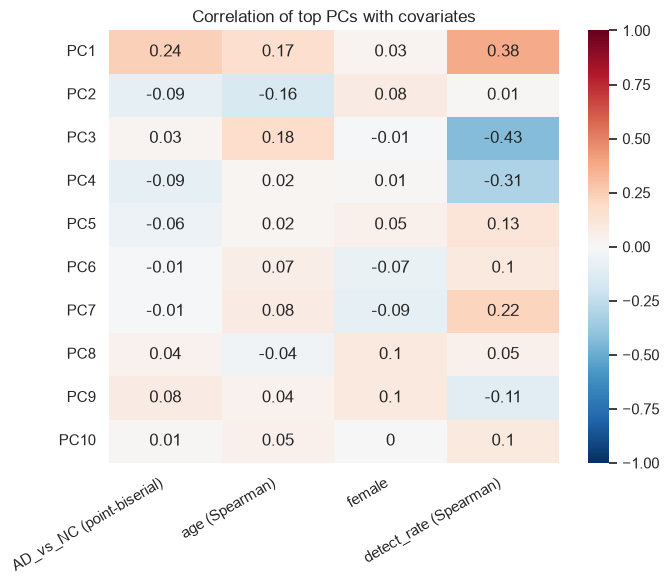

In [11]:
# What drives each top PC? Correlation of PCs with clinical / technical variables
drivers = pd.DataFrame({
    "AD_vs_NC (point-biserial)": [stats.pointbiserialr((pcs.diagnosis == "AD")[pcs.diagnosis.isin(["AD", "NC"])],
                                   pcs.loc[pcs.diagnosis.isin(["AD", "NC"]), f"PC{i}"])[0] for i in range(1, 11)],
    "age (Spearman)": [stats.spearmanr(pcs.age, pcs[f"PC{i}"])[0] for i in range(1, 11)],
    "female": [stats.pointbiserialr(pcs.sex == "female", pcs[f"PC{i}"])[0] for i in range(1, 11)],
    "detect_rate (Spearman)": [stats.spearmanr(pcs.detect_rate, pcs[f"PC{i}"])[0] for i in range(1, 11)],
}, index=[f"PC{i}" for i in range(1, 11)]).round(2)

plt.figure(figsize=(7, 6))
sns.heatmap(drivers, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation of top PCs with covariates"); plt.yticks(rotation=0); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); savefig("pca_drivers"); plt.show()

**How to read this.** If PC1/PC2 correlate mostly with `detect_rate`, the largest source of variation is
technical (sample quality), not disease. Disease signal in serum miRNA is usually subtle and appears in
later PCs or only in supervised analysis.

In [12]:
# Outliers: samples far from the centre in the top 10 PCs (robust z-score > 4 on any PC)
pc_vals = pcs[[f"PC{i}" for i in range(1, 11)]]
robust_z = (pc_vals - pc_vals.median()) / (1.4826 * (pc_vals - pc_vals.median()).abs().median())
outliers = robust_z.abs().max(axis=1) > 4
print(f"Potential outliers (|robust z| > 4 on any of PC1-10): {outliers.sum()}")
clin.loc[outliers[outliers].index, ["diagnosis", "age", "sex", "detect_rate"]].assign(
    max_abs_z=robust_z.abs().max(axis=1)[outliers]).sort_values("max_abs_z", ascending=False).head(20)

Potential outliers (|robust z| > 4 on any of PC1-10): 20


,diagnosis,age,sex,detect_rate,max_abs_z
sample,,,,,
GSM3404218,AD,85.0,female,0.358314,8.576105
GSM3405299,VaD,63.0,male,0.604215,7.196440
GSM3404014,AD,83.0,female,0.202576,7.136613
GSM3404786,DLB,77.0,male,0.271272,6.507395
GSM3404789,DLB,78.0,male,0.430133,5.256890
GSM3403775,AD,78.0,female,0.542935,5.222795
GSM3403979,AD,88.0,female,0.147931,5.011139
GSM3404788,DLB,81.0,male,0.348946,4.943957
GSM3403914,AD,86.0,female,0.213895,4.868920


Outliers are **flagged, not removed** here. Decide removal rules in the analysis plan; if removed,
the same rule must be applied inside cross-validation and to external datasets.

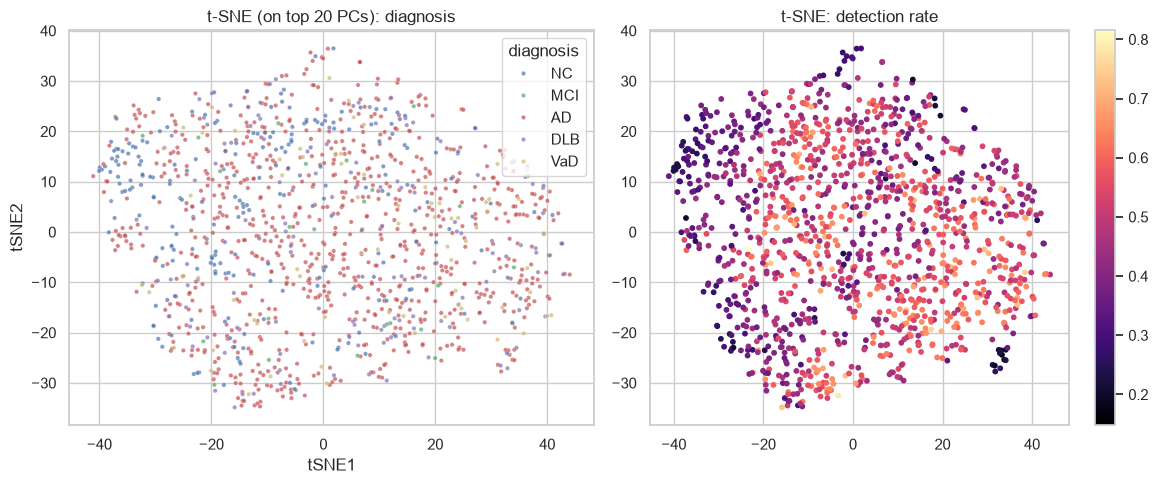

In [13]:
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca")
emb = pd.DataFrame(tsne.fit_transform(pca.transform(Z)[:, :20]), index=Xf.index, columns=["tSNE1", "tSNE2"]).join(clin)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=emb, x="tSNE1", y="tSNE2", hue="diagnosis", hue_order=DX_ORDER, palette=PALETTE,
                s=10, alpha=.7, ax=axes[0]); axes[0].set_title("t-SNE (on top 20 PCs): diagnosis")
sc = axes[1].scatter(emb.tSNE1, emb.tSNE2, c=emb.detect_rate, cmap="magma", s=10)
plt.colorbar(sc, ax=axes[1]); axes[1].set_title("t-SNE: detection rate")
plt.tight_layout(); savefig("tsne"); plt.show()

## 5. AD vs NC: univariate differences

Three tests per miRNA (training split, AD vs NC only):
- **Unadjusted:** Mann-Whitney U test
- **Adjusted:** linear model `miRNA ~ AD + age + sex + APOE4` (coefficient for AD)
- **Adjusted + quality:** same model plus `detect_rate` (sample quality, see section 2)

FDR correction: Benjamini-Hochberg. miRNAs significant only before age adjustment are likely age-driven.

*Note: this is exploration. Feature selection for modeling will be repeated inside cross-validation.*

In [14]:
mask = clin.diagnosis.isin(["AD", "NC"])
Xa, ca = Xf[mask], clin[mask]
is_ad = (ca.diagnosis == "AD").astype(int)

cov = pd.DataFrame({"const": 1.0, "AD": is_ad, "age": ca.age,
                    "female": (ca.sex == "female").astype(int), "apoe4": ca.apoe4}, index=ca.index)

rows = []
for m in Xa.columns:
    y = Xa[m]
    u = stats.mannwhitneyu(y[is_ad == 1], y[is_ad == 0])
    fit = sm.OLS(y, cov).fit()
    fit_q = sm.OLS(y, cov.assign(detect_rate=ca.detect_rate)).fit()
    pooled_sd = y.std()
    rows.append({"miRNA": m,
                 "log2FC": y[is_ad == 1].mean() - y[is_ad == 0].mean(),
                 "effect_d": (y[is_ad == 1].mean() - y[is_ad == 0].mean()) / pooled_sd,
                 "auc": u.statistic / (is_ad.sum() * (1 - is_ad).sum()),
                 "p_raw": u.pvalue,
                 "beta_adj": fit.params["AD"], "p_adj": fit.pvalues["AD"],
                 "beta_age": fit.params["age"], "p_age": fit.pvalues["age"],
                 "beta_adj_q": fit_q.params["AD"], "p_adj_q": fit_q.pvalues["AD"]})
de = pd.DataFrame(rows).set_index("miRNA")
de["fdr_raw"] = multipletests(de.p_raw, method="fdr_bh")[1]
de["fdr_adj"] = multipletests(de.p_adj, method="fdr_bh")[1]
de["fdr_age"] = multipletests(de.p_age, method="fdr_bh")[1]
de["fdr_adj_q"] = multipletests(de.p_adj_q, method="fdr_bh")[1]
de = de.sort_values("p_adj")

print(f"Significant AD vs NC (FDR < 0.05), unadjusted:  {(de.fdr_raw < .05).sum()}")
print(f"Significant AD vs NC (FDR < 0.05), age/sex/APOE4-adjusted: {(de.fdr_adj < .05).sum()}")
print(f"Lost after adjustment (likely confounded): {((de.fdr_raw < .05) & (de.fdr_adj >= .05)).sum()}")
print(f"Significant after also adjusting for detect_rate: {(de.fdr_adj_q < .05).sum()}")
sig = de.fdr_adj < .05
print(f"Direction (adjusted): {(sig & (de.beta_adj > 0)).sum()} higher in AD, {(sig & (de.beta_adj < 0)).sum()} lower in AD")
de.to_csv(OUT / "01_eda_AD_vs_NC_univariate.csv")
de.head(15).round(4)

Significant AD vs NC (FDR < 0.05), unadjusted:  494
Significant AD vs NC (FDR < 0.05), age/sex/APOE4-adjusted: 331
Lost after adjustment (likely confounded): 188
Significant after also adjusting for detect_rate: 263
Direction (adjusted): 293 higher in AD, 38 lower in AD


,log2FC,effect_d,auc,p_raw,beta_adj,p_adj,beta_age,p_age,beta_adj_q,p_adj_q,fdr_raw,fdr_adj,fdr_age,fdr_adj_q
miRNA,,,,,,,,,,,,,,
hsa-miR-6761-3p,0.4128,0.6206,0.6800,0.0,0.4177,0.0,-0.0001,0.9874,0.3231,0.0,0.0,0.0,0.9887,0.0000
hsa-miR-4713-5p,0.3198,0.5663,0.6507,0.0,0.3322,0.0,-0.0029,0.3012,0.2437,0.0,0.0,0.0,0.4221,0.0000
hsa-miR-4685-3p,0.3258,0.5332,0.6583,0.0,0.3545,0.0,-0.0037,0.2170,0.2610,0.0,0.0,0.0,0.3304,0.0000
hsa-miR-6786-3p,0.2774,0.5572,0.6602,0.0,0.2873,0.0,-0.0017,0.4890,0.2261,0.0,0.0,0.0,0.5999,0.0000
hsa-miR-3622a-3p,0.3501,0.5758,0.6704,0.0,0.3498,0.0,-0.0001,0.9811,0.2870,0.0,0.0,0.0,0.9859,0.0000
hsa-miR-3184-5p,-0.3558,-0.6626,0.3066,0.0,-0.2972,0.0,-0.0051,0.0518,-0.3151,0.0,0.0,0.0,0.1066,0.0000
hsa-miR-1229-3p,0.2833,0.5785,0.6605,0.0,0.2737,0.0,0.0005,0.8280,0.2217,0.0,0.0,0.0,0.8785,0.0000
hsa-miR-6743-3p,0.2644,0.5342,0.6468,0.0,0.2751,0.0,-0.0007,0.7906,0.2018,0.0,0.0,0.0,0.8510,0.0000
hsa-miR-6759-3p,0.2461,0.5188,0.6513,0.0,0.2593,0.0,-0.0004,0.8666,0.1988,0.0,0.0,0.0,0.9042,0.0000


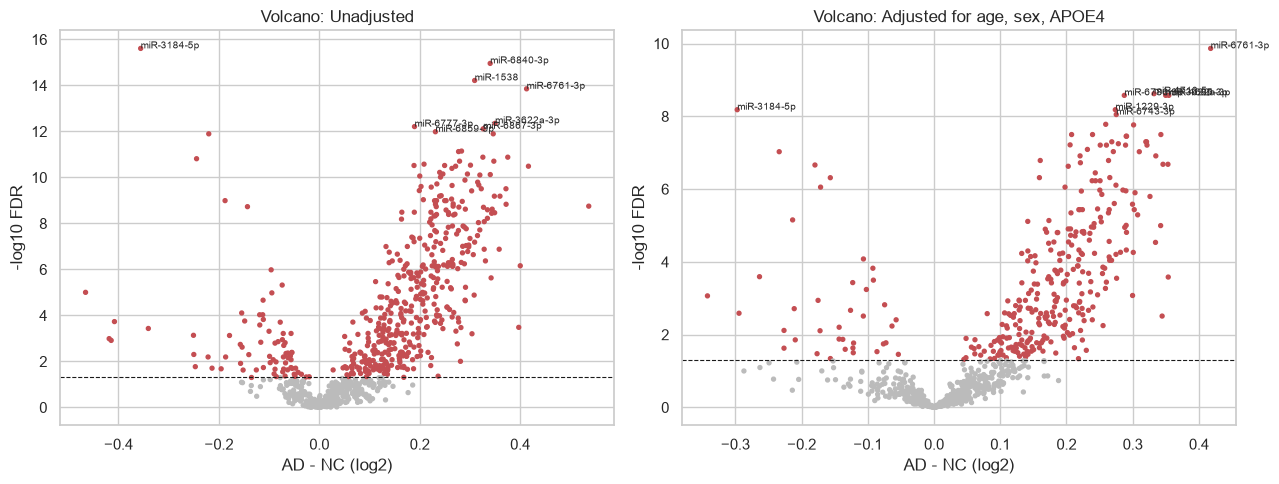

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (b, f, title) in zip(axes, [("log2FC", "fdr_raw", "Unadjusted"),
                                    ("beta_adj", "fdr_adj", "Adjusted for age, sex, APOE4")]):
    sig = de[f] < 0.05
    ax.scatter(de[b], -np.log10(de[f]), c=np.where(sig, "#C44E52", "#BBBBBB"), s=8)
    for m in de[sig].sort_values(f).head(8).index:
        ax.annotate(m.replace("hsa-", ""), (de.loc[m, b], -np.log10(de.loc[m, f])), fontsize=7)
    ax.axhline(-np.log10(.05), ls="--", c="k", lw=.8)
    ax.set_xlabel("AD - NC (log2)"); ax.set_ylabel("-log10 FDR"); ax.set_title(f"Volcano: {title}")
plt.tight_layout(); savefig("volcano"); plt.show()

In [16]:
# Single-miRNA AUC distribution: how strong is the best individual marker?
print("Top 10 single-miRNA AUCs (AD vs NC, >0.5 = higher in AD):")
best = de.assign(auc_dir=np.maximum(de.auc, 1 - de.auc)).sort_values("auc_dir", ascending=False)
best[["auc", "log2FC", "fdr_adj"]].head(10).round(3)

Top 10 single-miRNA AUCs (AD vs NC, >0.5 = higher in AD):


,auc,log2FC,fdr_adj
miRNA,,,
hsa-miR-3184-5p,0.307,-0.356,0.0
hsa-miR-6840-3p,0.688,0.340,0.0
hsa-miR-1538,0.683,0.309,0.0
hsa-miR-6761-3p,0.680,0.413,0.0
hsa-miR-3622a-3p,0.670,0.350,0.0
hsa-miR-6777-3p,0.669,0.190,0.0
hsa-miR-6867-3p,0.668,0.326,0.0
hsa-miR-6859-3p,0.667,0.231,0.0
hsa-miR-128-1-5p,0.334,-0.220,0.0


## 6. Age-related miRNAs (within controls only)

miRNAs with |rho| > 0.3 vs age in controls: 11


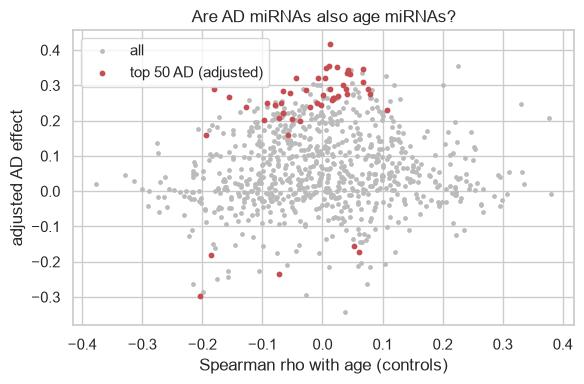

In [17]:
ncm = clin.diagnosis == "NC"
age_cor = pd.Series({m: stats.spearmanr(clin.loc[ncm, "age"], Xf.loc[ncm, m])[0] for m in Xf.columns})
print(f"miRNAs with |rho| > 0.3 vs age in controls: {(age_cor.abs() > .3).sum()}")

top_ad = de.index[:50]
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(age_cor[de.index], de.beta_adj, s=6, c="#BBBBBB", label="all")
ax.scatter(age_cor[top_ad], de.loc[top_ad, "beta_adj"], s=10, c="#C44E52", label="top 50 AD (adjusted)")
ax.set_xlabel("Spearman rho with age (controls)"); ax.set_ylabel("adjusted AD effect")
ax.legend(); ax.set_title("Are AD miRNAs also age miRNAs?")
plt.tight_layout(); savefig("age_vs_ad_effect"); plt.show()
de["age_rho_NC"] = age_cor

## 7. Known AD ncRNAs from the literature

Most classic AD miRNAs are **poorly detected** in serum on this array, so they fail the detection filter.
They are tested here anyway (all training AD vs NC samples), with their detection rate shown,
to see whether the literature markers carry any signal in this dataset.

In [18]:
known = load_known_ncrnas()
known_mir = known[known.type == "miRNA"]["name"]

def find(n):
    for c in [n, n + "-5p", n + "-3p"]:
        if c in X.columns:
            return c

rows = []
for n in known_mir:
    f = find(n)
    if f is None:
        continue
    y = X.loc[mask, f]
    u = stats.mannwhitneyu(y[is_ad == 1], y[is_ad == 0])
    fit = sm.OLS(y, cov).fit()
    rows.append({"name": n, "feature": f, "detect_rate": round(mirna_detect[f], 2),
                 "passes_filter": f in keep, "log2FC": y[is_ad == 1].mean() - y[is_ad == 0].mean(),
                 "auc": u.statistic / (is_ad.sum() * (1 - is_ad).sum()), "p_raw": u.pvalue,
                 "beta_adj": fit.params["AD"], "p_adj": fit.pvalues["AD"]})
k = pd.DataFrame(rows)
k["fdr_adj"] = multipletests(k.p_adj, method="fdr_bh")[1]   # FDR within the known-miRNA set
k.to_csv(OUT / "01_eda_known_mirnas.csv", index=False)
print(f"Known miRNAs passing the {MIN_DETECT:.0%} detection filter: {k.passes_filter.sum()} / {len(k)}")
print(f"Known miRNAs with adjusted FDR < 0.05 (within this set): {(k.fdr_adj < .05).sum()}")
k.sort_values("p_adj").round(3)

Known miRNAs passing the 80% detection filter: 0 / 24
Known miRNAs with adjusted FDR < 0.05 (within this set): 15


,name,feature,detect_rate,passes_filter,log2FC,auc,p_raw,beta_adj,p_adj,fdr_adj
2,hsa-miR-29c-3p,hsa-miR-29c-3p,0.23,False,-0.187,0.447,0.013,-0.376,0.000,0.003
12,hsa-miR-128-3p,hsa-miR-128-3p,0.17,False,-0.112,0.466,0.116,-0.342,0.000,0.005
6,hsa-miR-132-3p,hsa-miR-132-3p,0.29,False,-0.121,0.457,0.047,-0.316,0.001,0.006
3,hsa-miR-107,hsa-miR-107,0.29,False,-0.103,0.469,0.146,-0.326,0.001,0.007
22,hsa-miR-501-3p,hsa-miR-501-3p,0.04,False,-0.080,0.469,0.156,-0.291,0.002,0.008
4,hsa-miR-146a-5p,hsa-miR-146a-5p,0.16,False,-0.053,0.473,0.213,-0.282,0.003,0.010
10,hsa-miR-181c-5p,hsa-miR-181c-5p,0.08,False,-0.057,0.477,0.296,-0.275,0.004,0.010
17,hsa-miR-155-5p,hsa-miR-155-5p,0.07,False,-0.066,0.471,0.178,-0.273,0.004,0.010
23,hsa-miR-26b-5p,hsa-miR-26b-5p,0.10,False,-0.052,0.480,0.342,-0.272,0.004,0.010
21,hsa-miR-455-3p,hsa-miR-455-3p,0.09,False,-0.018,0.483,0.426,-0.263,0.006,0.014


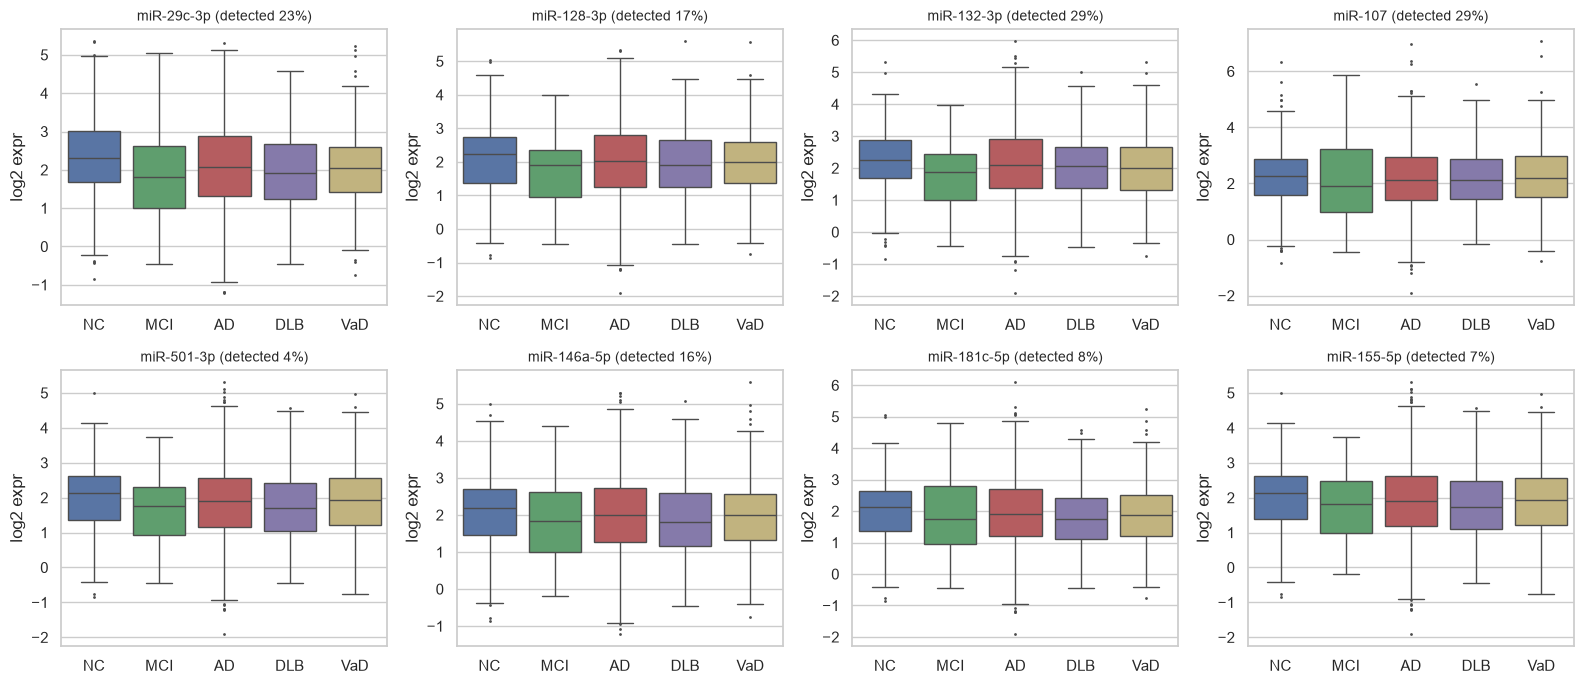

In [19]:
show = k.sort_values("p_adj").feature.head(8)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, m in zip(axes.flat, show):
    sns.boxplot(data=clin.assign(v=X[m]), x="diagnosis", y="v", order=DX_ORDER, hue="diagnosis", legend=False,
                palette=PALETTE, ax=ax, fliersize=1)
    ax.set_title(f"{m.replace('hsa-', '')} (detected {mirna_detect[m]:.0%})", fontsize=10)
    ax.set_ylabel("log2 expr"); ax.set_xlabel("")
plt.tight_layout(); savefig("known_mirnas_boxplots"); plt.show()

## 8. Summary and outputs

In [20]:
filt = pd.DataFrame({"miRNA": keep, "detect_rate": mirna_detect[keep].values})
filt.to_csv(OUT / "01_eda_filtered_mirnas.csv", index=False)
clin[["detect_rate"]].to_csv(OUT / "01_eda_sample_detect_rate.csv")
pd.DataFrame({"outlier": outliers}).to_csv(OUT / "01_eda_outlier_flags.csv")

print("Saved:")
for f in sorted(OUT.glob("01_eda_*")): print("  ", f.relative_to(ROOT))
print("Figures in", FIG.relative_to(ROOT))

Saved:
   results/tables/01_eda_AD_vs_NC_univariate.csv
   results/tables/01_eda_filtered_mirnas.csv
   results/tables/01_eda_known_mirnas.csv
   results/tables/01_eda_outlier_flags.csv
   results/tables/01_eda_sample_detect_rate.csv
Figures in results/figures/01_eda


### Findings to record (fill in after running)

- Age / sex / APOE4 imbalance between AD and NC:
- Detection rate differs by diagnosis? Correlated with age?
- Main drivers of PC1/PC2 (disease, age, or sample quality):
- Number of outliers flagged, and decision:
- Number of significant miRNAs before vs after age adjustment:
- Best single-miRNA AUC:
- Known AD miRNAs that replicate here:

### Decisions for the modeling notebook
- `MIN_DETECT` threshold:
- Include `detect_rate` as a covariate?
- Outlier rule: